In [1]:

# Step 7.1A — Inspect saved data for arXiv diffusion analysis

from pathlib import Path
import pandas as pd
import numpy as np
import networkx as nx

# Locate project root
project_folder = Path.cwd().resolve()

if project_folder.name == "notebooks":
    project_folder = project_folder.parent

results_folder = project_folder / "results"
data_folder = project_folder / "data"

print("PROJECT ROOT")
print(project_folder)

print("\nSAVED ARXIV FILES")
print("-" * 55)

for path in sorted(results_folder.glob("arxiv_*.csv")):
    print(path.name)

print("\nDATA FOLDER CONTENTS")
print("-" * 55)

if data_folder.exists():
    for path in sorted(data_folder.iterdir()):
        print(path.name)
else:
    print("Data folder not found.")

# Load the original selected node IDs
subset_nodes_df = pd.read_csv(
    results_folder / "arxiv_subset_node_ids.csv"
)

# Load the previously calculated influence scores
influence_df = pd.read_csv(
    results_folder / "arxiv_influence_results.csv"
)

# Load Louvain community memberships
membership_df = pd.read_csv(
    results_folder / "arxiv_louvain_membership.csv"
)

print("\nVALIDATION")
print("Selected nodes:", len(subset_nodes_df))
print("Influence records:", len(influence_df))
print("Community memberships:", len(membership_df))

print("\nINFLUENCE DATA COLUMNS")
print(influence_df.columns.tolist())

print("\nSAMPLE INFLUENCE DATA")
display(influence_df.head(3))

assert len(subset_nodes_df) == 5000
assert len(membership_df) == 5000
assert subset_nodes_df["node idx"].is_unique
assert membership_df["node idx"].is_unique

print("\nInitial validation passed!")


PROJECT ROOT
C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis

SAVED ARXIV FILES
-------------------------------------------------------
arxiv_betweenness_sensitivity.csv
arxiv_community_agreement.csv
arxiv_community_stability_runs.csv
arxiv_community_stability_summary.csv
arxiv_community_topic_counts.csv
arxiv_community_topic_percentages.csv
arxiv_community_topic_summary.csv
arxiv_influence_correlations.csv
arxiv_influence_results.csv
arxiv_influence_top10_overlap.csv
arxiv_louvain_membership.csv
arxiv_paper_topics.csv
arxiv_subset_metadata.csv
arxiv_subset_node_ids.csv
arxiv_topic_community_agreement.csv
arxiv_topic_community_assignments.csv
arxiv_topic_summary.csv

DATA FOLDER CONTENTS
-------------------------------------------------------
.gitkeep
ogbn_arxiv

VALIDATION
Selected nodes: 5000
Influence records: 5000
Community memberships: 5000

INFLUENCE DATA COLUMNS
['node idx', 'degree_centrality', 'in_degree', 'out_degree', 'pagerank', 'paper id', 'title', 'be

,node idx,degree_centrality,in_degree,out_degree,pagerank,paper id,title,betweenness
0,0,0.013403,65,2,0.001001,9657784,evasion attacks against machine learning at te...,0.000870
1,31,0.001200,3,3,0.000075,1585744708,learning transformations for clustering and cl...,0.000217
2,65,0.001600,2,6,0.000070,1814471488,improved analysis for subspace pursuit algorit...,0.000016



Initial validation passed!


In [2]:

# Step 7.1B — Reconstruct the original 5,000-node citation graph

import networkx as nx
import numpy as np
from ogb.nodeproppred import NodePropPredDataset

# Load the original OGBN-Arxiv dataset
dataset = NodePropPredDataset(
    name="ogbn-arxiv",
    root=str(data_folder / "ogbn_arxiv")
)

graph_data, labels = dataset[0]

# Original directed citation edges
edge_index = graph_data["edge_index"]

# Load our previously selected 5,000 nodes
selected_nodes = set(
    subset_nodes_df["node idx"].astype(int)
)

# Reconstruct the directed subgraph
G_directed = nx.DiGraph()
G_directed.add_nodes_from(selected_nodes)

# Keep edges where both endpoints belong to our subset
subset_edges = [
    (int(source), int(target))
    for source, target in edge_index.T
    if int(source) in selected_nodes
    and int(target) in selected_nodes
]

G_directed.add_edges_from(subset_edges)

# Reconstruct the undirected graph used for Louvain
G_subset = G_directed.to_undirected()

print("DIRECTED CITATION NETWORK")
print("Nodes:", G_directed.number_of_nodes())
print("Edges:", G_directed.number_of_edges())

print("\nUNDIRECTED CITATION NETWORK")
print("Nodes:", G_subset.number_of_nodes())
print("Edges:", G_subset.number_of_edges())

print("\nVALIDATION")
assert G_directed.number_of_nodes() == 5000
assert G_subset.number_of_nodes() == 5000

# Expected counts from our earlier analysis
assert G_directed.number_of_edges() == 27284
assert G_subset.number_of_edges() == 26953

assert set(G_directed.nodes()) == selected_nodes

print("Original arXiv subgraph reconstructed successfully!")


Downloaded 0.08 GB: 100%|██████████| 81/81 [00:59<00:00,  1.36it/s]


Extracting C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\data\ogbn_arxiv\arxiv.zip
Loading necessary files...
This might take a while.
Processing graphs...


100%|██████████| 1/1 [00:00<?, ?it/s]

Saving...


DIRECTED CITATION NETWORK
Nodes: 5000
Edges: 27284

UNDIRECTED CITATION NETWORK
Nodes: 5000
Edges: 26953

VALIDATION
Original arXiv subgraph reconstructed successfully!


In [3]:

# Step 7.2A — Construct knowledge-flow network

# Reverse citation edges:
# citing -> cited becomes cited -> citing

G_diffusion = G_directed.reverse(copy=True)

print("KNOWLEDGE-FLOW NETWORK")
print("-" * 45)
print("Nodes:", G_diffusion.number_of_nodes())
print("Edges:", G_diffusion.number_of_edges())

# Verify graph structure
assert G_diffusion.number_of_nodes() == 5000
assert G_diffusion.number_of_edges() == 27284

# Verify each reversed edge
assert all(
    G_directed.has_edge(target, source)
    for source, target in G_diffusion.edges()
)

print("\nKnowledge-flow directions validated!")

# Inspect an example edge
source, target = next(iter(G_diffusion.edges()))

print("\nEXAMPLE")
print(f"Original citation: {target} -> {source}")
print(f"Knowledge flow:    {source} -> {target}")


KNOWLEDGE-FLOW NETWORK
---------------------------------------------
Nodes: 5000
Edges: 27284

Knowledge-flow directions validated!

EXAMPLE
Original citation: 65762 -> 0
Knowledge flow:    0 -> 65762


In [4]:

# Step 7.2B — Implement Independent Cascade diffusion

import numpy as np

def independent_cascade(graph, seeds, p=0.1, random_seed=42):
    """
    Simulate information diffusion using Independent Cascade.

    Parameters
    ----------
    graph : networkx.DiGraph
        Directed knowledge-flow network.
    seeds : list
        Initially activated nodes.
    p : float
        Probability of activating each inactive outgoing neighbour.
    random_seed : int
        Random seed for reproducibility.

    Returns
    -------
    dict
        Total spread, number of rounds and activation history.
    """

    if not 0 <= p <= 1:
        raise ValueError("Activation probability must be between 0 and 1.")

    if not set(seeds).issubset(graph.nodes):
        raise ValueError("All seed nodes must exist in the graph.")

    rng = np.random.default_rng(random_seed)

    active = set(seeds)
    newly_active = set(seeds)

    activation_history = [len(active)]

    while newly_active:
        next_active = set()

        for node in newly_active:
            for neighbour in graph.successors(node):

                if neighbour in active or neighbour in next_active:
                    continue

                if rng.random() < p:
                    next_active.add(neighbour)

        if not next_active:
            break

        active.update(next_active)
        newly_active = next_active

        activation_history.append(len(active))

    return {
        "total_spread": len(active),
        "rounds": len(activation_history) - 1,
        "activation_history": activation_history
    }


# Test using the paper with the highest in-degree
top_paper = int(
    influence_df.sort_values(
        "in_degree",
        ascending=False
    ).iloc[0]["node idx"]
)

test_result = independent_cascade(
    graph=G_diffusion,
    seeds=[top_paper],
    p=0.1,
    random_seed=42
)

print("INDEPENDENT CASCADE TEST")
print("-" * 45)
print("Seed paper:", top_paper)
print("Activation probability:", 0.1)
print("Total activated papers:", test_result["total_spread"])
print("Diffusion rounds:", test_result["rounds"])
print("Activation history:", test_result["activation_history"])

# Basic validation
assert 1 <= test_result["total_spread"] <= 5000
assert test_result["activation_history"][0] == 1
assert test_result["activation_history"][-1] == test_result["total_spread"]

print("\nIndependent Cascade simulation completed successfully!")


INDEPENDENT CASCADE TEST
---------------------------------------------
Seed paper: 47283
Activation probability: 0.1
Total activated papers: 62
Diffusion rounds: 4
Activation history: [1, 53, 58, 61, 62]

Independent Cascade simulation completed successfully!


In [5]:

# Step 7.2C — Validate Independent Cascade behaviour

# Test 1: No propagation when p = 0
zero_result = independent_cascade(
    G_diffusion,
    seeds=[top_paper],
    p=0.0,
    random_seed=42
)

assert zero_result["total_spread"] == 1

# Test 2: Full propagation to all reachable nodes when p = 1
full_result = independent_cascade(
    G_diffusion,
    seeds=[top_paper],
    p=1.0,
    random_seed=42
)

reachable_nodes = nx.descendants(
    G_diffusion,
    top_paper
)

expected_spread = len(reachable_nodes) + 1

assert full_result["total_spread"] == expected_spread

# Test 3: Reproducibility
repeat_result = independent_cascade(
    G_diffusion,
    seeds=[top_paper],
    p=0.1,
    random_seed=42
)

assert repeat_result == test_result

print("INDEPENDENT CASCADE VALIDATION")
print("-" * 50)

print("Test 1 — p = 0")
print("Observed spread:", zero_result["total_spread"])
print("Expected spread: 1")
print("PASS")

print("\nTest 2 — p = 1")
print("Observed spread:", full_result["total_spread"])
print("Expected spread:", expected_spread)
print("PASS")

print("\nTest 3 — Reproducibility")
print("Repeated spread:", repeat_result["total_spread"])
print("Original spread:", test_result["total_spread"])
print("PASS")

print("\nAll Independent Cascade validation tests passed!")


INDEPENDENT CASCADE VALIDATION
--------------------------------------------------
Test 1 — p = 0
Observed spread: 1
Expected spread: 1
PASS

Test 2 — p = 1
Observed spread: 2457
Expected spread: 2457
PASS

Test 3 — Reproducibility
Repeated spread: 62
Original spread: 62
PASS

All Independent Cascade validation tests passed!


In [6]:

# Step 7.3A — Monte Carlo evaluation of information spread

import numpy as np
import pandas as pd
import time

def monte_carlo_spread(
    graph,
    seeds,
    p=0.1,
    n_simulations=100,
    random_seed=42
):
    """
    Estimate expected Independent Cascade spread using
    repeated simulations with different random seeds.
    """

    if n_simulations < 2:
        raise ValueError("Use at least 2 simulations.")

    spreads = []

    start_time = time.perf_counter()

    for simulation in range(n_simulations):

        result = independent_cascade(
            graph=graph,
            seeds=seeds,
            p=p,
            random_seed=random_seed + simulation
        )

        spreads.append(result["total_spread"])

    runtime = time.perf_counter() - start_time

    return {
        "seed_count": len(seeds),
        "activation_probability": p,
        "n_simulations": n_simulations,
        "mean_spread": np.mean(spreads),
        "std_spread": np.std(spreads, ddof=1),
        "min_spread": np.min(spreads),
        "max_spread": np.max(spreads),
        "runtime_seconds": runtime,
        "spreads": spreads
    }


# Test Monte Carlo evaluation on our original seed paper
mc_test = monte_carlo_spread(
    graph=G_diffusion,
    seeds=[top_paper],
    p=0.1,
    n_simulations=100,
    random_seed=42
)

print("MONTE CARLO DIFFUSION TEST")
print("-" * 50)

print("Seed paper:", top_paper)
print("Activation probability:", mc_test["activation_probability"])
print("Simulations:", mc_test["n_simulations"])

print("\nSPREAD RESULTS")
print(f"Mean spread: {mc_test['mean_spread']:.2f}")
print(f"Standard deviation: {mc_test['std_spread']:.2f}")
print(f"Minimum spread: {mc_test['min_spread']}")
print(f"Maximum spread: {mc_test['max_spread']}")
print(f"Runtime: {mc_test['runtime_seconds']:.2f} seconds")

assert len(mc_test["spreads"]) == 100
assert mc_test["min_spread"] >= 1
assert mc_test["max_spread"] <= 5000

print("\nMonte Carlo evaluation completed successfully!")


MONTE CARLO DIFFUSION TEST
--------------------------------------------------
Seed paper: 47283
Activation probability: 0.1
Simulations: 100

SPREAD RESULTS
Mean spread: 66.58
Standard deviation: 9.61
Minimum spread: 44
Maximum spread: 99
Runtime: 0.12 seconds

Monte Carlo evaluation completed successfully!


In [7]:

# Step 7.3B — Prepare seed-selection strategies

SEED_BUDGET = 10
RANDOM_SEED = 42

# Combine influence scores and Louvain communities
seed_candidates_df = influence_df.merge(
    membership_df,
    on="node idx",
    how="inner",
    validate="one_to_one"
)

assert len(seed_candidates_df) == 5000

# Strategy 1: Random selection
rng = np.random.default_rng(RANDOM_SEED)

random_seeds = rng.choice(
    seed_candidates_df["node idx"].to_numpy(),
    size=SEED_BUDGET,
    replace=False
).astype(int).tolist()

# Strategy 2: Highest degree centrality
degree_seeds = (
    seed_candidates_df
    .sort_values(
        ["degree_centrality", "node idx"],
        ascending=[False, True]
    )
    .head(SEED_BUDGET)["node idx"]
    .astype(int)
    .tolist()
)

# Strategy 3: Highest PageRank
pagerank_seeds = (
    seed_candidates_df
    .sort_values(
        ["pagerank", "node idx"],
        ascending=[False, True]
    )
    .head(SEED_BUDGET)["node idx"]
    .astype(int)
    .tolist()
)

# Strategy 4: Community-aware selection
# Select one highest-degree paper from each of the
# 10 largest Louvain communities.

largest_communities = (
    seed_candidates_df["louvain_community"]
    .value_counts()
    .head(SEED_BUDGET)
    .index
    .tolist()
)

community_seeds = []

for community_id in largest_communities:
    candidates = seed_candidates_df[
        seed_candidates_df["louvain_community"] == community_id
    ]

    top_candidate = (
        candidates
        .sort_values(
            ["degree_centrality", "node idx"],
            ascending=[False, True]
        )
        .iloc[0]
    )

    community_seeds.append(int(top_candidate["node idx"]))

# Store all strategies
seed_strategies = {
    "Random": random_seeds,
    "Degree": degree_seeds,
    "PageRank": pagerank_seeds,
    "Community-aware": community_seeds
}

# Validate all strategies
for strategy, seeds in seed_strategies.items():
    assert len(seeds) == SEED_BUDGET
    assert len(set(seeds)) == SEED_BUDGET
    assert set(seeds).issubset(G_diffusion.nodes())

# Display selected seeds
seed_selection_rows = []

for strategy, seeds in seed_strategies.items():
    for node in seeds:
        seed_selection_rows.append({
            "strategy": strategy,
            "node idx": node
        })

seed_selection_df = pd.DataFrame(seed_selection_rows)

seed_selection_df = seed_selection_df.merge(
    seed_candidates_df[
        ["node idx", "title", "louvain_community",
         "degree_centrality", "pagerank"]
    ],
    on="node idx",
    how="left"
)

print("SEED-SELECTION SUMMARY")
print("-" * 55)

summary = (
    seed_selection_df
    .groupby("strategy")
    .agg(
        n_seeds=("node idx", "size"),
        communities_covered=("louvain_community", "nunique"),
        mean_degree_centrality=("degree_centrality", "mean")
    )
)

display(summary.round(4))

print("\nSELECTED PAPERS")
display(
    seed_selection_df[
        ["strategy", "node idx", "louvain_community", "title"]
    ]
)

print("\nAll four seed-selection strategies validated!")


SEED-SELECTION SUMMARY
-------------------------------------------------------


,n_seeds,communities_covered,mean_degree_centrality
strategy,,,
Community-aware,10,10,0.0565
Degree,10,6,0.0613
PageRank,10,5,0.0458
Random,10,7,0.0010



SELECTED PAPERS


,strategy,node idx,louvain_community,title
0,Random,14906,12,exact learning from an honest teacher that ans...
1,Random,128803,0,make the minority great again first order regr...
2,Random,15354,3,differentially private iterative synchronous c...
3,Random,109508,7,compact hyperplane hashing with bilinear funct...
4,Random,73526,10,pooling or sampling collective dynamics for el...
5,Random,72727,3,benefits and pitfalls of the exponential mecha...
6,Random,116265,8,orthonet multilayer network data clustering
7,Random,15813,0,minimizing dynamic regret and adaptive regret ...
8,Random,33448,10,a parallel solver for graph laplacians
9,Random,144877,13,deja vu an empirical evaluation of the memoriz...



All four seed-selection strategies validated!


In [8]:

# Step 7.3C — Compare four seed-selection strategies

comparison_results = []
simulation_records = []

for strategy, seeds in seed_strategies.items():

    result = monte_carlo_spread(
        graph=G_diffusion,
        seeds=seeds,
        p=0.1,
        n_simulations=100,
        random_seed=42
    )

    communities_covered = (
        seed_candidates_df
        .set_index("node idx")
        .loc[seeds, "louvain_community"]
        .nunique()
    )

    comparison_results.append({
        "strategy": strategy,
        "seed_budget": len(seeds),
        "activation_probability": 0.1,
        "n_simulations": 100,
        "communities_covered": communities_covered,
        "mean_spread": result["mean_spread"],
        "std_spread": result["std_spread"],
        "min_spread": result["min_spread"],
        "max_spread": result["max_spread"],
        "runtime_seconds": result["runtime_seconds"]
    })

    for simulation_id, spread in enumerate(result["spreads"]):
        simulation_records.append({
            "strategy": strategy,
            "simulation_id": simulation_id,
            "spread": spread
        })

# Create result tables
diffusion_comparison_df = pd.DataFrame(comparison_results)

diffusion_comparison_df = (
    diffusion_comparison_df
    .sort_values("mean_spread", ascending=False)
    .reset_index(drop=True)
)

diffusion_simulations_df = pd.DataFrame(simulation_records)

print("DIFFUSION STRATEGY COMPARISON")
print("-" * 65)

display(
    diffusion_comparison_df[
        [
            "strategy",
            "communities_covered",
            "mean_spread",
            "std_spread",
            "min_spread",
            "max_spread"
        ]
    ].round(2)
)

print("\nTOTAL SIMULATIONS:", len(diffusion_simulations_df))

print(
    "TOTAL RUNTIME:",
    round(diffusion_comparison_df["runtime_seconds"].sum(), 2),
    "seconds"
)

# Validate results
assert len(diffusion_comparison_df) == 4
assert len(diffusion_simulations_df) == 400

assert diffusion_comparison_df["mean_spread"].between(
    10, 5000
).all()

print("\nFour-strategy comparison completed successfully!")


DIFFUSION STRATEGY COMPARISON
-----------------------------------------------------------------


,strategy,communities_covered,mean_spread,std_spread,min_spread,max_spread
0,PageRank,5,450.76,53.64,355,593
1,Degree,6,437.11,36.90,341,557
2,Community-aware,10,413.58,45.36,314,530
3,Random,7,12.49,2.11,10,21



TOTAL SIMULATIONS: 400
TOTAL RUNTIME: 1.18 seconds

Four-strategy comparison completed successfully!


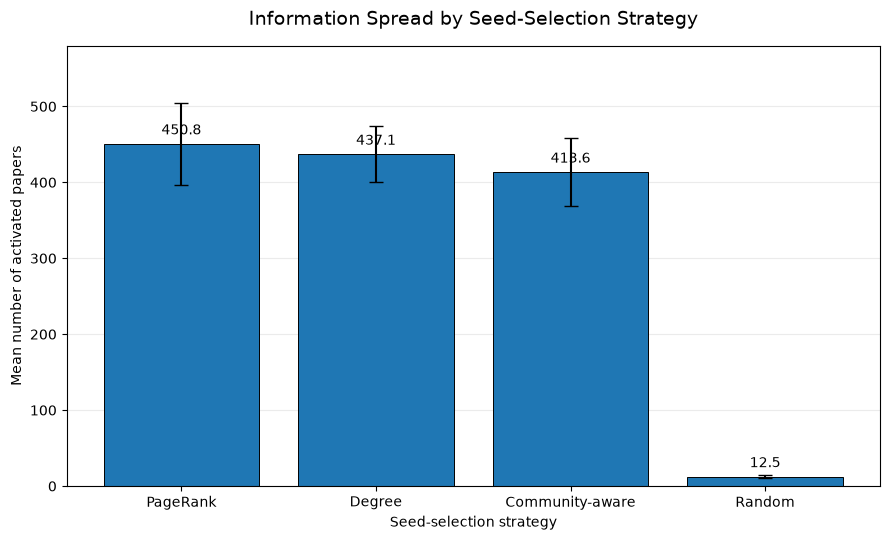

FILES SAVED
-------------------------------------------------------
1. arxiv_diffusion_strategy_comparison.csv
2. arxiv_diffusion_simulations.csv
3. arxiv_diffusion_seed_selection.csv
4. arxiv_diffusion_strategy_comparison.png

Figure location: ..\figures\arxiv_diffusion_strategy_comparison.png


In [18]:

# Step 7.3D — Save diffusion results and create comparison figure

import matplotlib.pyplot as plt

# Save summary and individual simulation results
diffusion_comparison_df.to_csv(
    results_folder / "arxiv_diffusion_strategy_comparison.csv",
    index=False
)

diffusion_simulations_df.to_csv(
    results_folder / "arxiv_diffusion_simulations.csv",
    index=False
)

seed_selection_df.to_csv(
    results_folder / "arxiv_diffusion_seed_selection.csv",
    index=False
)

# Create comparison figure
fig, ax = plt.subplots(figsize=(9, 5.5))

strategies = diffusion_comparison_df["strategy"]
means = diffusion_comparison_df["mean_spread"]
stds = diffusion_comparison_df["std_spread"]

bars = ax.bar(
    strategies,
    means,
    yerr=stds,
    capsize=5,
    edgecolor="black",
    linewidth=0.7
)

ax.set_title(
    "Information Spread by Seed-Selection Strategy",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Seed-selection strategy")
ax.set_ylabel("Mean number of activated papers")

ax.set_ylim(0, max(means + stds) * 1.15)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

for bar, mean in zip(bars, means):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 8,
        f"{mean:.1f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()

figure_path = (
    figures_folder / "arxiv_diffusion_strategy_comparison.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("FILES SAVED")
print("-" * 55)
print("1. arxiv_diffusion_strategy_comparison.csv")
print("2. arxiv_diffusion_simulations.csv")
print("3. arxiv_diffusion_seed_selection.csv")
print("4. arxiv_diffusion_strategy_comparison.png")

print("\nFigure location:", figure_path)


In [19]:

# Fix: Define the figures folder and save the existing plot

from pathlib import Path

figures_folder = Path("..") / "figures"
figures_folder.mkdir(parents=True, exist_ok=True)

figure_path = (
    figures_folder / "arxiv_diffusion_strategy_comparison.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print("Figure saved successfully!")
print("Location:", figure_path.resolve())

print("\nSaved results:")
for filename in [
    "arxiv_diffusion_strategy_comparison.csv",
    "arxiv_diffusion_simulations.csv",
    "arxiv_diffusion_seed_selection.csv"
]:
    path = results_folder / filename
    print(filename, "—", "FOUND" if path.exists() else "MISSING")


Figure saved successfully!
Location: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\figures\arxiv_diffusion_strategy_comparison.png

Saved results:
arxiv_diffusion_strategy_comparison.csv — FOUND
arxiv_diffusion_simulations.csv — FOUND
arxiv_diffusion_seed_selection.csv — FOUND


In [21]:

# Fix: Define project root and commit diffusion results

from pathlib import Path
import subprocess

ROOT = Path.cwd().resolve().parent

print("Project root:", ROOT)
assert (ROOT / ".git").exists(), "Git repository not found!"
assert (ROOT / "notebooks").exists()

files_to_commit = [
    "notebooks/08_arxiv_diffusion.ipynb",
    "results/arxiv_diffusion_strategy_comparison.csv",
    "results/arxiv_diffusion_simulations.csv",
    "results/arxiv_diffusion_seed_selection.csv",
    "figures/arxiv_diffusion_strategy_comparison.png"
]

def run_git(*args):
    result = subprocess.run(
        ["git", *args],
        cwd=ROOT,
        capture_output=True,
        text=True
    )
    print(result.stdout or result.stderr or "Command completed.")
    if result.returncode != 0:
        raise RuntimeError(f"Git command failed: {' '.join(args)}")
    return result

# Verify all files exist before staging
for filename in files_to_commit:
    assert (ROOT / filename).exists(), f"Missing: {filename}"

run_git("add", "--", *files_to_commit)
run_git("diff", "--cached", "--stat")
run_git(
    "commit",
    "-m",
    "Add arXiv Independent Cascade diffusion comparison"
)
run_git("push")

print("\nDiffusion experiment committed and pushed successfully!")


Project root: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis
Command completed.
Command completed.
On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   notebooks/01_data_exploration.ipynb
	modified:   notebooks/02_community_detection.ipynb
	modified:   notebooks/03_influence_analysis.ipynb
	modified:   notebooks/04_diffusion_simulation.ipynb
	modified:   notebooks/05_large_network_analysis.ipynb
	modified:   notebooks/06_nlp_topic_modeling.ipynb
	modified:   notebooks/07_topic_aware_network_analysis.ipynb

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	data/ogbn_arxiv/
	results/arxiv_subset_metadata.csv

no changes added to commit (use "git add" and/or "git commit -a")



RuntimeError: Git command failed: commit -m Add arXiv Independent Cascade diffusion comparison

In [22]:

# Step 7.3E — Commit initial diffusion experiment

import subprocess

# Save the notebook in Jupyter before running this cell.

files_to_commit = [
    "notebooks/08_arxiv_diffusion.ipynb",
    "results/arxiv_diffusion_strategy_comparison.csv",
    "results/arxiv_diffusion_simulations.csv",
    "results/arxiv_diffusion_seed_selection.csv",
    "figures/arxiv_diffusion_strategy_comparison.png"
]

def run_git(*args):
    result = subprocess.run(
        ["git", *args],
        cwd=ROOT,
        capture_output=True,
        text=True
    )
    print(result.stdout or result.stderr)
    if result.returncode != 0:
        raise RuntimeError(f"Git command failed: {' '.join(args)}")
    return result

# Stage only this experiment's files
run_git("add", "--", *files_to_commit)

# Check staged changes
run_git("diff", "--cached", "--stat")

# Commit
run_git(
    "commit",
    "-m",
    "Add arXiv Independent Cascade diffusion comparison"
)

# Push to GitHub
run_git("push")

print("Initial diffusion experiment committed and pushed!")




On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   notebooks/01_data_exploration.ipynb
	modified:   notebooks/02_community_detection.ipynb
	modified:   notebooks/03_influence_analysis.ipynb
	modified:   notebooks/04_diffusion_simulation.ipynb
	modified:   notebooks/05_large_network_analysis.ipynb
	modified:   notebooks/06_nlp_topic_modeling.ipynb
	modified:   notebooks/07_topic_aware_network_analysis.ipynb

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	data/ogbn_arxiv/
	results/arxiv_subset_metadata.csv

no changes added to commit (use "git add" and/or "git commit -a")



RuntimeError: Git command failed: commit -m Add arXiv Independent Cascade diffusion comparison

In [23]:

# Step 7.4A — Activation probability sensitivity analysis

activation_probabilities = [0.01, 0.05, 0.10, 0.20]

probability_results = []

for p in activation_probabilities:

    for strategy, seeds in seed_strategies.items():

        result = monte_carlo_spread(
            graph=G_diffusion,
            seeds=seeds,
            p=p,
            n_simulations=100,
            random_seed=42
        )

        probability_results.append({
            "strategy": strategy,
            "activation_probability": p,
            "seed_budget": len(seeds),
            "mean_spread": result["mean_spread"],
            "std_spread": result["std_spread"],
            "min_spread": result["min_spread"],
            "max_spread": result["max_spread"]
        })

probability_results_df = pd.DataFrame(probability_results)

# Compare strategies at each activation probability
probability_comparison = probability_results_df.pivot(
    index="activation_probability",
    columns="strategy",
    values="mean_spread"
)

print("ACTIVATION PROBABILITY SENSITIVITY")
print("-" * 65)

display(probability_comparison.round(2))

print("\nBEST STRATEGY AT EACH PROBABILITY")

for p, row in probability_comparison.iterrows():
    print(
        f"p = {p:.2f}: "
        f"{row.idxmax()} "
        f"(mean spread = {row.max():.2f})"
    )

# Validation
assert len(probability_results_df) == 16
assert probability_results_df["mean_spread"].between(
    10, 5000
).all()

print("\nSensitivity analysis completed successfully!")


ACTIVATION PROBABILITY SENSITIVITY
-----------------------------------------------------------------


strategy,Community-aware,Degree,PageRank,Random
activation_probability,,,,
0.01,36.18,39.06,33.87,10.20
0.05,166.62,181.66,166.23,11.11
0.10,413.58,437.11,450.76,12.49
0.20,1177.64,1165.69,1323.06,17.19



BEST STRATEGY AT EACH PROBABILITY
p = 0.01: Degree (mean spread = 39.06)
p = 0.05: Degree (mean spread = 181.66)
p = 0.10: PageRank (mean spread = 450.76)
p = 0.20: PageRank (mean spread = 1323.06)

Sensitivity analysis completed successfully!


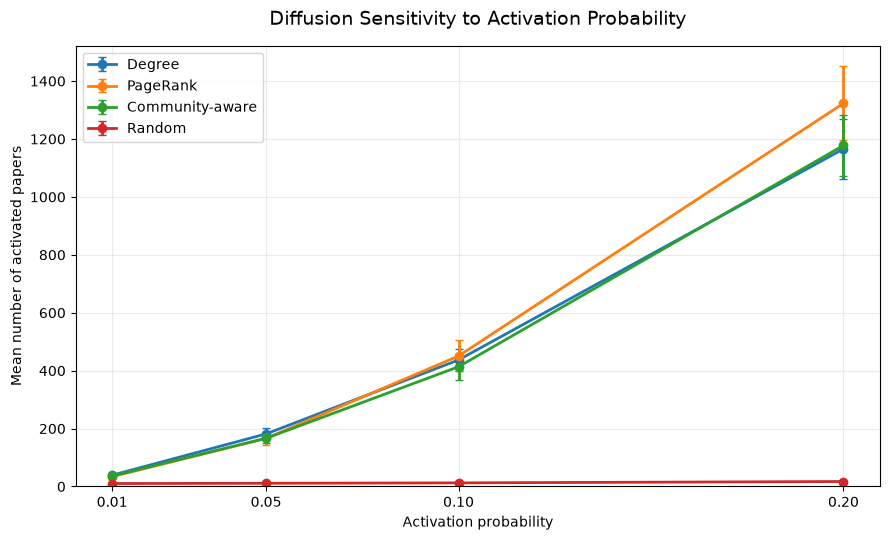

FILES SAVED
-------------------------------------------------------
C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\results\arxiv_diffusion_probability_sensitivity.csv
C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\figures\arxiv_diffusion_probability_sensitivity.png

Probability sensitivity results saved successfully!


In [24]:

# Step 7.4B — Save and visualise activation probability sensitivity

import matplotlib.pyplot as plt

# Save detailed results
probability_results_path = (
    results_folder / "arxiv_diffusion_probability_sensitivity.csv"
)

probability_results_df.to_csv(
    probability_results_path,
    index=False
)

# Create figure
fig, ax = plt.subplots(figsize=(9, 5.5))

strategy_order = [
    "Degree",
    "PageRank",
    "Community-aware",
    "Random"
]

for strategy in strategy_order:

    strategy_data = (
        probability_results_df[
            probability_results_df["strategy"] == strategy
        ]
        .sort_values("activation_probability")
    )

    ax.errorbar(
        strategy_data["activation_probability"],
        strategy_data["mean_spread"],
        yerr=strategy_data["std_spread"],
        marker="o",
        capsize=3,
        linewidth=2,
        label=strategy
    )

ax.set_title(
    "Diffusion Sensitivity to Activation Probability",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Activation probability")
ax.set_ylabel("Mean number of activated papers")

ax.set_xticks(activation_probabilities)
ax.set_ylim(bottom=0)

ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()

figure_path = (
    figures_folder / "arxiv_diffusion_probability_sensitivity.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Verify outputs
assert probability_results_path.exists()
assert figure_path.exists()

print("FILES SAVED")
print("-" * 55)
print(probability_results_path.resolve())
print(figure_path.resolve())

print("\nProbability sensitivity results saved successfully!")


In [25]:

# Step 7.4C — Seed-budget sensitivity analysis

seed_budgets = [1, 3, 5, 10]

budget_results = []

for budget in seed_budgets:

    for strategy, full_seeds in seed_strategies.items():

        selected_seeds = full_seeds[:budget]

        result = monte_carlo_spread(
            graph=G_diffusion,
            seeds=selected_seeds,
            p=0.10,
            n_simulations=100,
            random_seed=42
        )

        budget_results.append({
            "strategy": strategy,
            "seed_budget": budget,
            "activation_probability": 0.10,
            "mean_spread": result["mean_spread"],
            "std_spread": result["std_spread"],
            "min_spread": result["min_spread"],
            "max_spread": result["max_spread"]
        })

budget_results_df = pd.DataFrame(budget_results)

budget_comparison = budget_results_df.pivot(
    index="seed_budget",
    columns="strategy",
    values="mean_spread"
)

print("SEED-BUDGET SENSITIVITY")
print("-" * 65)

display(budget_comparison.round(2))

print("\nBEST STRATEGY AT EACH SEED BUDGET")

for budget, row in budget_comparison.iterrows():
    print(
        f"k = {budget}: "
        f"{row.idxmax()} "
        f"(mean spread = {row.max():.2f})"
    )

# Validate results
assert len(budget_results_df) == 16
assert budget_results_df["mean_spread"].between(
    budget_results_df["seed_budget"], 5000
).all()

print("\nSeed-budget sensitivity analysis completed successfully!")


SEED-BUDGET SENSITIVITY
-----------------------------------------------------------------


strategy,Community-aware,Degree,PageRank,Random
seed_budget,,,,
1,133.77,66.58,19.98,1.00
3,231.35,259.98,91.58,4.35
5,337.39,337.39,270.64,7.01
10,413.58,437.11,450.76,12.49



BEST STRATEGY AT EACH SEED BUDGET
k = 1: Community-aware (mean spread = 133.77)
k = 3: Degree (mean spread = 259.98)
k = 5: Community-aware (mean spread = 337.39)
k = 10: PageRank (mean spread = 450.76)

Seed-budget sensitivity analysis completed successfully!


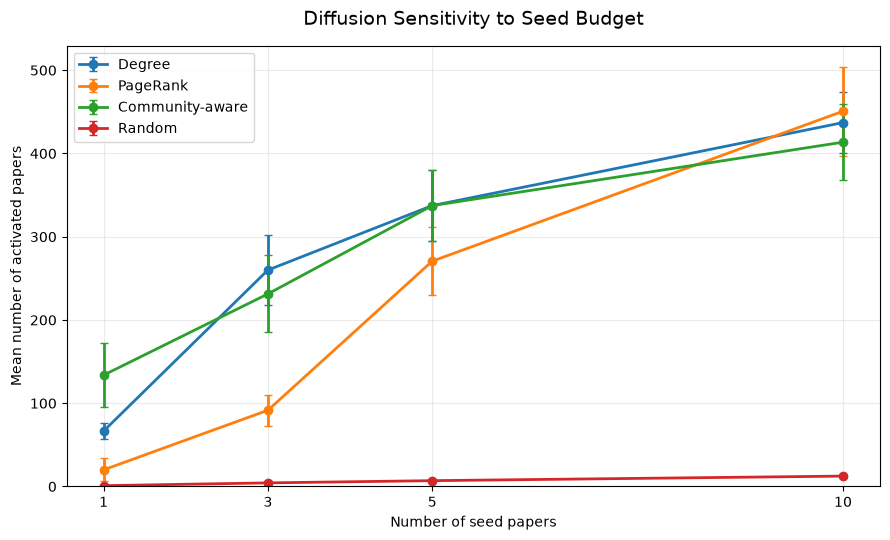

FILES SAVED
-------------------------------------------------------
C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\results\arxiv_diffusion_budget_sensitivity.csv
C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\figures\arxiv_diffusion_budget_sensitivity.png

Seed-budget sensitivity results saved successfully!


In [26]:

# Step 7.4D — Save and visualise seed-budget sensitivity

import matplotlib.pyplot as plt

# Save numerical results
budget_results_path = (
    results_folder / "arxiv_diffusion_budget_sensitivity.csv"
)

budget_results_df.to_csv(
    budget_results_path,
    index=False
)

# Plot mean spread by seed budget
fig, ax = plt.subplots(figsize=(9, 5.5))

strategy_order = [
    "Degree",
    "PageRank",
    "Community-aware",
    "Random"
]

for strategy in strategy_order:

    strategy_data = (
        budget_results_df[
            budget_results_df["strategy"] == strategy
        ]
        .sort_values("seed_budget")
    )

    ax.errorbar(
        strategy_data["seed_budget"],
        strategy_data["mean_spread"],
        yerr=strategy_data["std_spread"],
        marker="o",
        linewidth=2,
        capsize=3,
        label=strategy
    )

ax.set_title(
    "Diffusion Sensitivity to Seed Budget",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Number of seed papers")
ax.set_ylabel("Mean number of activated papers")

ax.set_xticks(seed_budgets)
ax.set_ylim(bottom=0)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

figure_path = (
    figures_folder / "arxiv_diffusion_budget_sensitivity.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

assert budget_results_path.exists()
assert figure_path.exists()

print("FILES SAVED")
print("-" * 55)
print(budget_results_path.resolve())
print(figure_path.resolve())

print("\nSeed-budget sensitivity results saved successfully!")


In [27]:

# Step 7.5A — Robustness of the random baseline

import numpy as np
import pandas as pd
import time

N_RANDOM_SETS = 100
N_SIMULATIONS = 100
SEED_BUDGET = 10
ACTIVATION_PROBABILITY = 0.10

rng = np.random.default_rng(2026)

all_nodes = np.array(
    sorted(G_diffusion.nodes()),
    dtype=int
)

random_baseline_results = []

start_time = time.perf_counter()

for set_id in range(N_RANDOM_SETS):

    # Independently select 10 random papers
    selected_seeds = rng.choice(
        all_nodes,
        size=SEED_BUDGET,
        replace=False
    ).astype(int).tolist()

    # Evaluate the selected seed set
    result = monte_carlo_spread(
        graph=G_diffusion,
        seeds=selected_seeds,
        p=ACTIVATION_PROBABILITY,
        n_simulations=N_SIMULATIONS,
        random_seed=10000 + set_id * N_SIMULATIONS
    )

    random_baseline_results.append({
        "set_id": set_id,
        "seed_budget": SEED_BUDGET,
        "activation_probability": ACTIVATION_PROBABILITY,
        "mean_spread": result["mean_spread"],
        "std_spread": result["std_spread"],
        "min_spread": result["min_spread"],
        "max_spread": result["max_spread"],
        "communities_covered": (
            seed_candidates_df
            .set_index("node idx")
            .loc[selected_seeds, "louvain_community"]
            .nunique()
        ),
        "seed_nodes": ",".join(map(str, selected_seeds))
    })

random_baseline_df = pd.DataFrame(random_baseline_results)

elapsed = time.perf_counter() - start_time

print("RANDOM BASELINE ROBUSTNESS")
print("-" * 60)
print("Independent random seed sets:", N_RANDOM_SETS)
print("Simulations per set:", N_SIMULATIONS)
print("Total simulations:", N_RANDOM_SETS * N_SIMULATIONS)

print("\nSPREAD ACROSS RANDOM SEED SETS")
print(
    f"Average mean spread: "
    f"{random_baseline_df['mean_spread'].mean():.2f}"
)
print(
    f"SD of set means: "
    f"{random_baseline_df['mean_spread'].std(ddof=1):.2f}"
)
print(
    f"Lowest set mean: "
    f"{random_baseline_df['mean_spread'].min():.2f}"
)
print(
    f"Highest set mean: "
    f"{random_baseline_df['mean_spread'].max():.2f}"
)

print("\nCOMMUNITY COVERAGE")
print(
    random_baseline_df["communities_covered"]
    .describe()
    .round(2)
)

print(f"\nRuntime: {elapsed:.2f} seconds")

assert len(random_baseline_df) == 100
assert random_baseline_df["mean_spread"].between(10, 5000).all()

print("\nRandom-baseline robustness test completed!")


RANDOM BASELINE ROBUSTNESS
------------------------------------------------------------
Independent random seed sets: 100
Simulations per set: 100
Total simulations: 10000

SPREAD ACROSS RANDOM SEED SETS
Average mean spread: 20.48
SD of set means: 11.32
Lowest set mean: 10.36
Highest set mean: 86.94

COMMUNITY COVERAGE
count    100.00
mean       6.67
std        0.99
min        4.00
25%        6.00
50%        7.00
75%        7.00
max        9.00
Name: communities_covered, dtype: float64

Runtime: 5.68 seconds

Random-baseline robustness test completed!


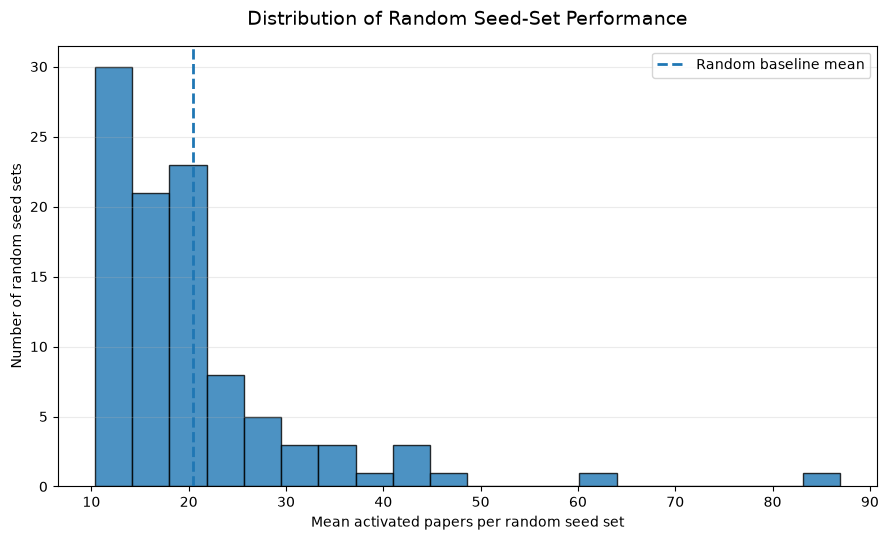

RANDOM BASELINE COMPARISON
-------------------------------------------------------
Random baseline mean: 20.48
Best random set mean: 86.94
PageRank: 450.76 (22.0x random mean)
Degree: 437.11 (21.3x random mean)
Community-aware: 413.58 (20.2x random mean)

Files saved successfully!
C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\results\arxiv_diffusion_random_baseline.csv
C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\figures\arxiv_diffusion_random_baseline.png


In [28]:

# Step 7.5B — Save and visualise random-baseline robustness

import matplotlib.pyplot as plt

# Save all random seed-set results
random_results_path = (
    results_folder / "arxiv_diffusion_random_baseline.csv"
)

random_baseline_df.to_csv(
    random_results_path,
    index=False
)

# Reference performance of the three influence strategies
reference_means = {
    "PageRank": 450.76,
    "Degree": 437.11,
    "Community-aware": 413.58
}

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.hist(
    random_baseline_df["mean_spread"],
    bins=20,
    edgecolor="black",
    alpha=0.8
)

ax.axvline(
    random_baseline_df["mean_spread"].mean(),
    linestyle="--",
    linewidth=2,
    label="Random baseline mean"
)

ax.set_title(
    "Distribution of Random Seed-Set Performance",
    fontsize=14,
    pad=15
)

ax.set_xlabel(
    "Mean activated papers per random seed set"
)
ax.set_ylabel("Number of random seed sets")

ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()

figure_path = (
    figures_folder / "arxiv_diffusion_random_baseline.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display reference comparison
print("RANDOM BASELINE COMPARISON")
print("-" * 55)

random_mean = random_baseline_df["mean_spread"].mean()

print(f"Random baseline mean: {random_mean:.2f}")
print(
    f"Best random set mean: "
    f"{random_baseline_df['mean_spread'].max():.2f}"
)

for strategy, mean_spread in reference_means.items():
    print(
        f"{strategy}: {mean_spread:.2f} "
        f"({mean_spread / random_mean:.1f}x random mean)"
    )

assert random_results_path.exists()
assert figure_path.exists()

print("\nFiles saved successfully!")
print(random_results_path.resolve())
print(figure_path.resolve())


In [29]:

# Step 7.6A — Bootstrap confidence intervals for strategy differences

import numpy as np
import pandas as pd

# Each row is one simulation ID; columns are strategies
paired_spreads = diffusion_simulations_df.pivot(
    index="simulation_id",
    columns="strategy",
    values="spread"
)

assert len(paired_spreads) == 100
assert not paired_spreads.isna().any().any()

comparisons = [
    ("PageRank", "Degree"),
    ("PageRank", "Community-aware"),
    ("Degree", "Community-aware")
]

N_BOOTSTRAPS = 10000
rng = np.random.default_rng(2026)

comparison_rows = []

for strategy_a, strategy_b in comparisons:

    differences = (
        paired_spreads[strategy_a].to_numpy()
        - paired_spreads[strategy_b].to_numpy()
    )

    observed_difference = differences.mean()

    # Resample matched simulation IDs
    bootstrap_indices = rng.integers(
        low=0,
        high=len(differences),
        size=(N_BOOTSTRAPS, len(differences))
    )

    bootstrap_means = differences[
        bootstrap_indices
    ].mean(axis=1)

    ci_lower, ci_upper = np.percentile(
        bootstrap_means,
        [2.5, 97.5]
    )

    comparison_rows.append({
        "strategy_a": strategy_a,
        "strategy_b": strategy_b,
        "mean_difference": observed_difference,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "ci_excludes_zero": (
            ci_lower > 0 or ci_upper < 0
        )
    })

bootstrap_comparison_df = pd.DataFrame(comparison_rows)

print("PAIRED BOOTSTRAP STRATEGY COMPARISON")
print("-" * 65)

display(bootstrap_comparison_df.round(2))

print("\nINTERPRETATION")

for _, row in bootstrap_comparison_df.iterrows():

    if row["ci_excludes_zero"]:
        conclusion = "CI excludes zero"
    else:
        conclusion = "CI includes zero"

    print(
        f"{row['strategy_a']} vs {row['strategy_b']}: "
        f"mean difference = {row['mean_difference']:.2f}, "
        f"95% CI [{row['ci_lower']:.2f}, "
        f"{row['ci_upper']:.2f}] — {conclusion}"
    )

print("\nBootstrap comparison completed successfully!")


PAIRED BOOTSTRAP STRATEGY COMPARISON
-----------------------------------------------------------------


,strategy_a,strategy_b,mean_difference,ci_lower,ci_upper,ci_excludes_zero
0,PageRank,Degree,13.65,4.18,23.47,True
1,PageRank,Community-aware,37.18,25.12,49.30,True
2,Degree,Community-aware,23.53,13.45,33.46,True



INTERPRETATION
PageRank vs Degree: mean difference = 13.65, 95% CI [4.18, 23.47] — CI excludes zero
PageRank vs Community-aware: mean difference = 37.18, 95% CI [25.12, 49.30] — CI excludes zero
Degree vs Community-aware: mean difference = 23.53, 95% CI [13.45, 33.46] — CI excludes zero

Bootstrap comparison completed successfully!


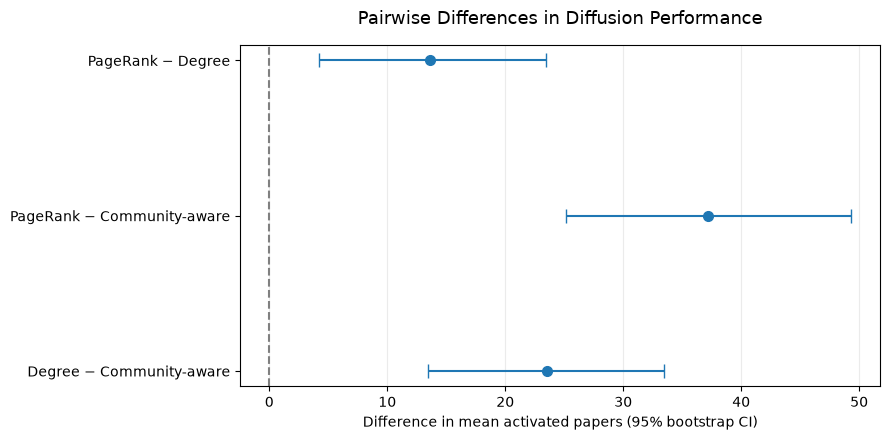

FILES SAVED
-------------------------------------------------------
C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\results\arxiv_diffusion_bootstrap_comparisons.csv
C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\figures\arxiv_diffusion_bootstrap_comparisons.png

Bootstrap comparison results saved successfully!


In [30]:

# Step 7.6B — Save bootstrap comparisons and plot confidence intervals

import matplotlib.pyplot as plt
import numpy as np

# Save statistical comparison table
bootstrap_results_path = (
    results_folder / "arxiv_diffusion_bootstrap_comparisons.csv"
)

bootstrap_comparison_df.to_csv(
    bootstrap_results_path,
    index=False
)

# Prepare comparison labels
labels = [
    f"{row['strategy_a']} − {row['strategy_b']}"
    for _, row in bootstrap_comparison_df.iterrows()
]

means = bootstrap_comparison_df["mean_difference"].to_numpy()
lower = bootstrap_comparison_df["ci_lower"].to_numpy()
upper = bootstrap_comparison_df["ci_upper"].to_numpy()

# Asymmetric confidence interval lengths
errors = np.vstack([
    means - lower,
    upper - means
])

fig, ax = plt.subplots(figsize=(9, 4.5))

positions = np.arange(len(labels))

ax.errorbar(
    means,
    positions,
    xerr=errors,
    fmt="o",
    capsize=5,
    markersize=7
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1.5,
    color="gray"
)

ax.set_yticks(positions)
ax.set_yticklabels(labels)
ax.invert_yaxis()

ax.set_xlabel(
    "Difference in mean activated papers (95% bootstrap CI)"
)

ax.set_title(
    "Pairwise Differences in Diffusion Performance",
    fontsize=13,
    pad=15
)

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()

figure_path = (
    figures_folder / "arxiv_diffusion_bootstrap_comparisons.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

assert bootstrap_results_path.exists()
assert figure_path.exists()

print("FILES SAVED")
print("-" * 55)
print(bootstrap_results_path.resolve())
print(figure_path.resolve())

print("\nBootstrap comparison results saved successfully!")


In [31]:

# Step 7.7A — Audit diffusion files in Git

from pathlib import Path
import subprocess

ROOT = Path.cwd().resolve().parent

assert (ROOT / ".git").exists(), "Project repository not found"

def git_check(*args):
    result = subprocess.run(
        ["git", *args],
        cwd=ROOT,
        capture_output=True,
        text=True
    )
    if result.returncode != 0:
        raise RuntimeError(result.stderr)
    return result.stdout.strip()

diffusion_files = [
    "notebooks/08_arxiv_diffusion.ipynb",
    "results/arxiv_diffusion_strategy_comparison.csv",
    "results/arxiv_diffusion_simulations.csv",
    "results/arxiv_diffusion_seed_selection.csv",
    "figures/arxiv_diffusion_strategy_comparison.png",
    "results/arxiv_diffusion_probability_sensitivity.csv",
    "figures/arxiv_diffusion_probability_sensitivity.png",
    "results/arxiv_diffusion_budget_sensitivity.csv",
    "figures/arxiv_diffusion_budget_sensitivity.png",
    "results/arxiv_diffusion_random_baseline.csv",
    "figures/arxiv_diffusion_random_baseline.png",
    "results/arxiv_diffusion_bootstrap_comparisons.csv",
    "figures/arxiv_diffusion_bootstrap_comparisons.png"
]

print("DIFFUSION FILE AUDIT")
print("-" * 70)

for filename in diffusion_files:

    exists = (ROOT / filename).exists()

    tracked = bool(
        git_check("ls-files", "--", filename)
    )

    ignored = bool(
        git_check("ls-files", "--others", "--ignored",
                  "--exclude-standard", "--", filename)
    )

    status = (
        "TRACKED" if tracked
        else "IGNORED" if ignored
        else "UNTRACKED"
    )

    print(
        f"{status:<12} "
        f"{'EXISTS' if exists else 'MISSING':<8} "
        f"{filename}"
    )

print("\nCURRENT GIT STATUS")
print("-" * 70)
print(git_check("status", "--short") or "Working tree clean")

print("\nLATEST COMMIT")
print(git_check("log", "-1", "--oneline"))


DIFFUSION FILE AUDIT
----------------------------------------------------------------------
TRACKED      EXISTS   notebooks/08_arxiv_diffusion.ipynb
TRACKED      EXISTS   results/arxiv_diffusion_strategy_comparison.csv
TRACKED      EXISTS   results/arxiv_diffusion_simulations.csv
TRACKED      EXISTS   results/arxiv_diffusion_seed_selection.csv
TRACKED      EXISTS   figures/arxiv_diffusion_strategy_comparison.png
UNTRACKED    EXISTS   results/arxiv_diffusion_probability_sensitivity.csv
UNTRACKED    EXISTS   figures/arxiv_diffusion_probability_sensitivity.png
UNTRACKED    EXISTS   results/arxiv_diffusion_budget_sensitivity.csv
UNTRACKED    EXISTS   figures/arxiv_diffusion_budget_sensitivity.png
UNTRACKED    EXISTS   results/arxiv_diffusion_random_baseline.csv
UNTRACKED    EXISTS   figures/arxiv_diffusion_random_baseline.png
UNTRACKED    EXISTS   results/arxiv_diffusion_bootstrap_comparisons.csv
UNTRACKED    EXISTS   figures/arxiv_diffusion_bootstrap_comparisons.png

CURRENT GIT STATUS
--